# Mejora de generalización y transferencia — seguimiento experimental

Este notebook compara la referencia **stable v1** con una combinación convexa elegida en
validación, una red de dos torres con cabezas aditivas e interacción y una adaptación
supervisada al dominio PRISM. Todas las configuraciones se fijaron antes de observar sus
nuevos resultados de test. **Los datos ya habían sido examinados en fases anteriores**:
estos resultados son exploratorios, no una nueva validación externa confirmatoria.

Las cinco particiones cold-drug mantienen juntas las identidades químicas completas.
No se cambia el preprocessing guardado de la referencia. El experimento neuronal usa
un entorno Torch/CUDA distinto del entorno bloqueado de stable v1; sus versiones se
registran por separado. Las figuras exportan PNG a 300 dpi, SVG y PDF.


In [1]:
import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/improvement_v1.json").exists())
SOURCE = ROOT / "data/reports/improvement_v1_summary.json"
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == "964985ecedb0b7fef4f5640fa8f63b34be5d810f8e7f52c30fd1a06a53ebba15", "Snapshot modificado: reconstruir notebook"
S = json.loads(SOURCE.read_text(encoding="utf-8"))
M = pd.DataFrame(S["metrics"])
C = M[M["case"].str.startswith("cold_drug")].copy()
A = pd.DataFrame(S["adaptation"])
B = pd.DataFrame(S["bootstrap"])
D = pd.DataFrame(S["drug_diagnostics"])
H = pd.DataFrame(S["plot_data"]["histories"])
OUT = ROOT / "figures/improvement_v1"
OUT.mkdir(parents=True, exist_ok=True)
LABELS = {"B0": "Efectos medios", "RF_targets": "RF · targets", "RF_morgan": "RF · Morgan",
           "ensemble": "Ensemble validado", "neural": "Red · dos semillas"}
ORDER = list(LABELS)
COLORS = {"B0": "#8B96A5", "RF_targets": "#247A69", "RF_morgan": "#436EB3",
           "ensemble": "#D48927", "neural": "#9B5E9B"}
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.18,
                     "pdf.fonttype": 42, "svg.fonttype": "none"})
def save(fig, name):
    fig.tight_layout()
    for ext in ["png", "svg", "pdf"]:
        fig.savefig(OUT / (name + "." + ext), bbox_inches="tight", facecolor="white")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## 1. Fármacos nuevos: comparación principal

RMSE medio de cinco folds (barra: desviación entre folds, **no** intervalo de confianza).
Las redes seleccionan una de dos representaciones por RMSE del ensemble de dos semillas
en validación. El ensemble tabular elige pesos en una rejilla de 15 combinaciones,
sin consultar test. Cada modelo cubre los mismos 149 364 pares una vez.


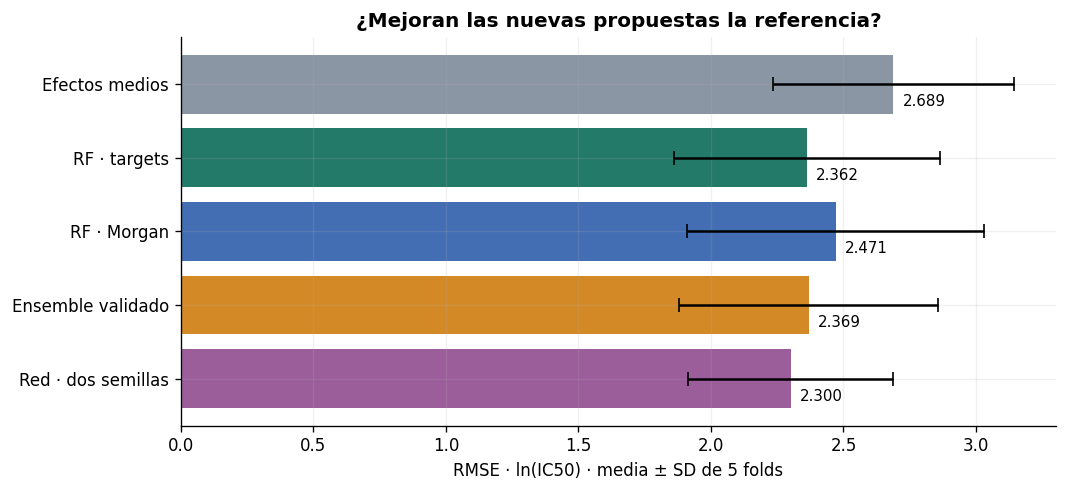

,rmse,sd,folds
label,,,
B0,2.688546,0.456061,5
RF_targets,2.362372,0.500490,5
RF_morgan,2.471001,0.560860,5
ensemble,2.369393,0.488899,5
neural,2.300128,0.385521,5


In [2]:
aggregate = C.groupby("label").agg(rmse=("rmse", "mean"), sd=("rmse", "std"), folds=("case", "nunique")).reindex(ORDER)
assert aggregate.folds.eq(5).all()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(range(5), aggregate.rmse, xerr=aggregate.sd, color=[COLORS[k] for k in ORDER], capsize=4)
ax.set_yticks(range(5), [LABELS[k] for k in ORDER]); ax.invert_yaxis()
ax.set_xlabel("RMSE · ln(IC50) · media ± SD de 5 folds")
ax.set_title("¿Mejoran las nuevas propuestas la referencia?")
for i, x in enumerate(aggregate.rmse): ax.text(x + 0.035, i + 0.3, f"{x:.3f}", fontsize=9)
save(fig, "01_cold_drug_rmse")
display(aggregate)

## 2. Consistencia entre folds

Delta frente a RF-targets sobre exactamente los mismos pares: negativo favorece
la propuesta. Estas cinco diferencias no representan cinco estudios independientes.
Se muestran además R² normalizado y Spearman medio dentro de cada fármaco, para separar
el error absoluto de la capacidad de ordenar sensibilidades celulares.


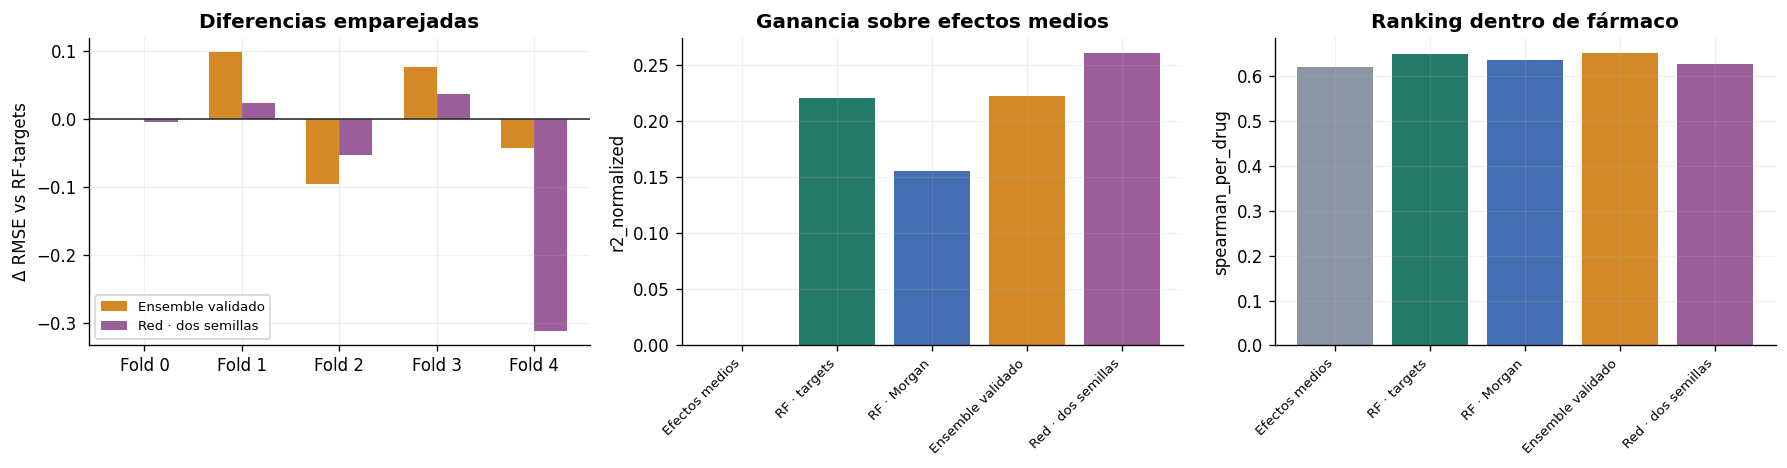

,case,label,rmse_delta,ci95_low,ci95_high
0,cold_drug_fold_0,ensemble,0.000000,0.000000,0.000000
1,cold_drug_fold_0,neural,-0.004725,-0.354553,0.357355
2,cold_drug_fold_1,ensemble,0.097938,0.030343,0.180401
3,cold_drug_fold_1,neural,0.022380,-0.321233,0.352695
4,cold_drug_fold_2,ensemble,-0.096131,-0.218495,0.021211
5,cold_drug_fold_2,neural,-0.053587,-0.306187,0.206205
6,cold_drug_fold_3,ensemble,0.075878,-0.191013,0.338420
7,cold_drug_fold_3,neural,0.036615,-0.215286,0.271099
8,cold_drug_fold_4,ensemble,-0.042579,-0.163577,0.071229
9,cold_drug_fold_4,neural,-0.311902,-1.019052,0.306393


In [3]:
pivot = C.pivot(index="case", columns="label", values="rmse")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(5)
for k, shift in [("ensemble", -0.17), ("neural", 0.17)]:
    axes[0].bar(x + shift, pivot[k] - pivot.RF_targets, width=0.34, label=LABELS[k], color=COLORS[k])
axes[0].axhline(0, color="#333333", lw=1); axes[0].set_xticks(x, [f"Fold {i}" for i in x])
axes[0].set_ylabel("Δ RMSE vs RF-targets"); axes[0].set_title("Diferencias emparejadas"); axes[0].legend(fontsize=8)
for ax, metric, title in [(axes[1], "r2_normalized", "Ganancia sobre efectos medios"),
                           (axes[2], "spearman_per_drug", "Ranking dentro de fármaco")]:
    vals = C.groupby("label")[metric].mean().reindex(ORDER)
    ax.bar(range(5), vals, color=[COLORS[k] for k in ORDER])
    ax.set_xticks(range(5), [LABELS[k] for k in ORDER], rotation=45, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylabel(metric)
save(fig, "02_folds_and_normalized_metrics")
display(B[B.case.str.startswith("cold_drug")][["case", "label", "rmse_delta", "ci95_low", "ci95_high"]])

Los intervalos anteriores remuestrean identidades químicas emparejadas
con modelos ya ajustados. No incluyen la incertidumbre de volver a entrenar ni corrigen
la exploración previa de este dataset. No se utiliza su resultado para retocar candidatos.

## 3. Aprendizaje de la red

Curvas de validación de cada semilla para la configuración elegida en cada fold.
Se guarda el checkpoint con menor RMSE de validación, no la última época.


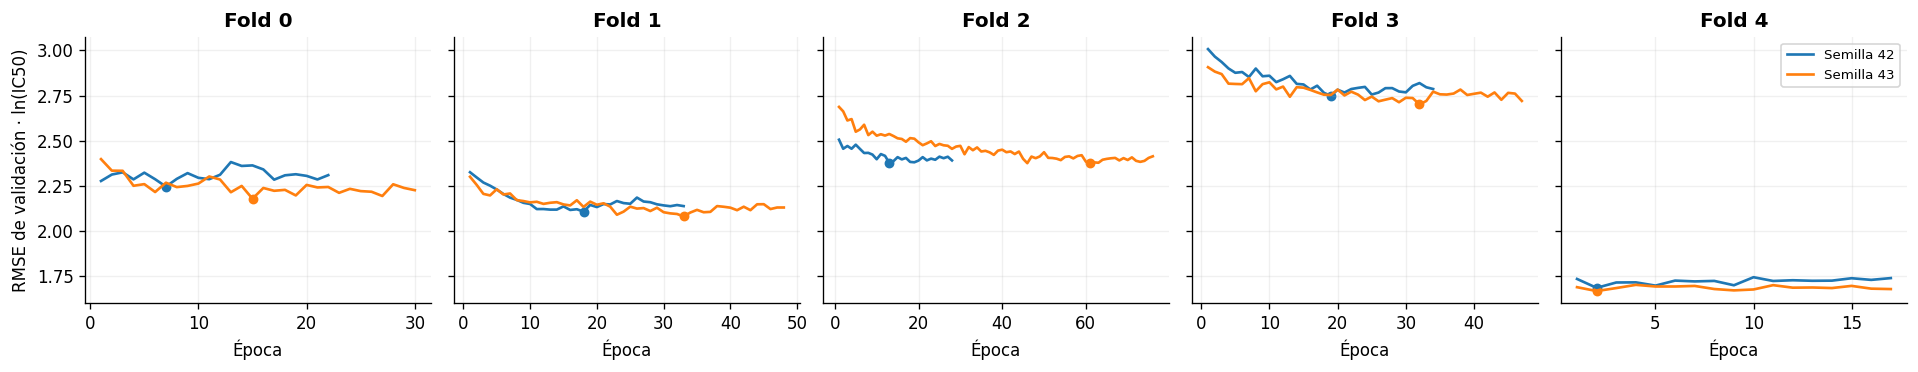

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for i, ax in enumerate(axes):
    data = H[H.case.eq(f"cold_drug_fold_{i}")]
    for seed, frame in data.groupby("seed"):
        ax.plot(frame.epoch, frame.validation_rmse, label=f"Semilla {seed}", lw=1.6)
        best = frame.loc[frame.validation_rmse.idxmin()]
        ax.scatter(best.epoch, best.validation_rmse, s=24)
    ax.set_title(f"Fold {i}"); ax.set_xlabel("Época")
axes[0].set_ylabel("RMSE de validación · ln(IC50)"); axes[-1].legend(fontsize=8)
save(fig, "03_neural_validation_learning")

## 4. Diagnóstico del error de la referencia

Cada punto es un fármaco de test. Para su similitud se usan sólo fingerprints de los
fármacos de entrenamiento de su fold. Compartir identidad está prohibido; compartir
subestructuras puede seguir ocurriendo. La figura es descriptiva, no una regla ajustada
para seleccionar modelos. Un target conocido significa un token presente en el vocabulario
de entrenamiento, no evidencia experimental de unión.


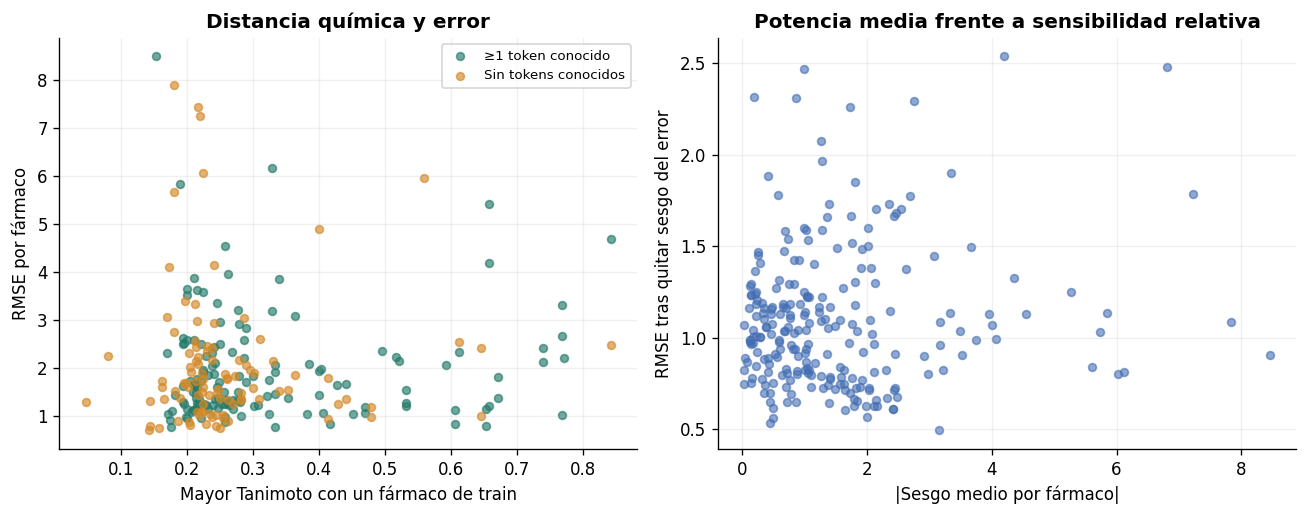

Fracción descriptiva del SSE atribuible al sesgo medio por fármaco: 76.6%


,name,n_pairs,rmse,bias,nearest_train_tanimoto,known_target_tokens
217,Romidepsin,555,8.501438,8.452875,0.153061,3
222,Dactinomycin,693,7.910137,7.835155,0.180124,0
229,Sepantronium bromide,708,7.446072,7.229067,0.216867,0
159,Daporinad,413,7.251375,6.814687,0.219780,0
156,Bortezomib,708,6.175726,6.122424,0.328571,1
92,glutathione,573,6.070264,-6.016806,0.223684,0
198,Staurosporine,716,5.964875,5.855664,0.558442,0
204,Dinaciclib,660,5.828481,5.736706,0.189655,2
215,Dactinomycin,555,5.672706,5.610569,0.180124,0
161,SN-38,707,5.423330,5.277730,0.657534,1


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for covered, color, label in [(True, "#247A69", "≥1 token conocido"), (False, "#D48927", "Sin tokens conocidos")]:
    frame = D[D.known_target_tokens.gt(0).eq(covered)]
    axes[0].scatter(frame.nearest_train_tanimoto, frame.rmse, s=22, alpha=0.65, color=color, label=label)
axes[0].set_xlabel("Mayor Tanimoto con un fármaco de train"); axes[0].set_ylabel("RMSE por fármaco")
axes[0].set_title("Distancia química y error"); axes[0].legend(fontsize=8)
axes[1].scatter(D.bias.abs(), D.centered_rmse, s=22, alpha=0.6, color="#436EB3")
axes[1].set_xlabel("|Sesgo medio por fármaco|"); axes[1].set_ylabel("RMSE tras quitar sesgo del error")
axes[1].set_title("Potencia media frente a sensibilidad relativa")
save(fig, "04_drug_error_diagnostics")
sse = (D.n_pairs * D.rmse**2).sum()
bias_sse = (D.n_pairs * D.bias**2).sum()
print(f"Fracción descriptiva del SSE atribuible al sesgo medio por fármaco: {bias_sse / sse:.1%}")
display(D.nlargest(12, "rmse")[["name", "n_pairs", "rmse", "bias", "nearest_train_tanimoto", "known_target_tokens"]])

## 5. Transferencia original, sin etiquetas PRISM para ajustar modelos

Cada panel compara modelos dentro de un mismo endpoint y una misma población.
El AUC publicado y el AUC de ventana armonizada tienen definiciones y distribuciones
diferentes: sus RMSE absolutos no se interpretan como una mejora entre endpoints.
La selección de pesos y redes utiliza únicamente validación GDSC.


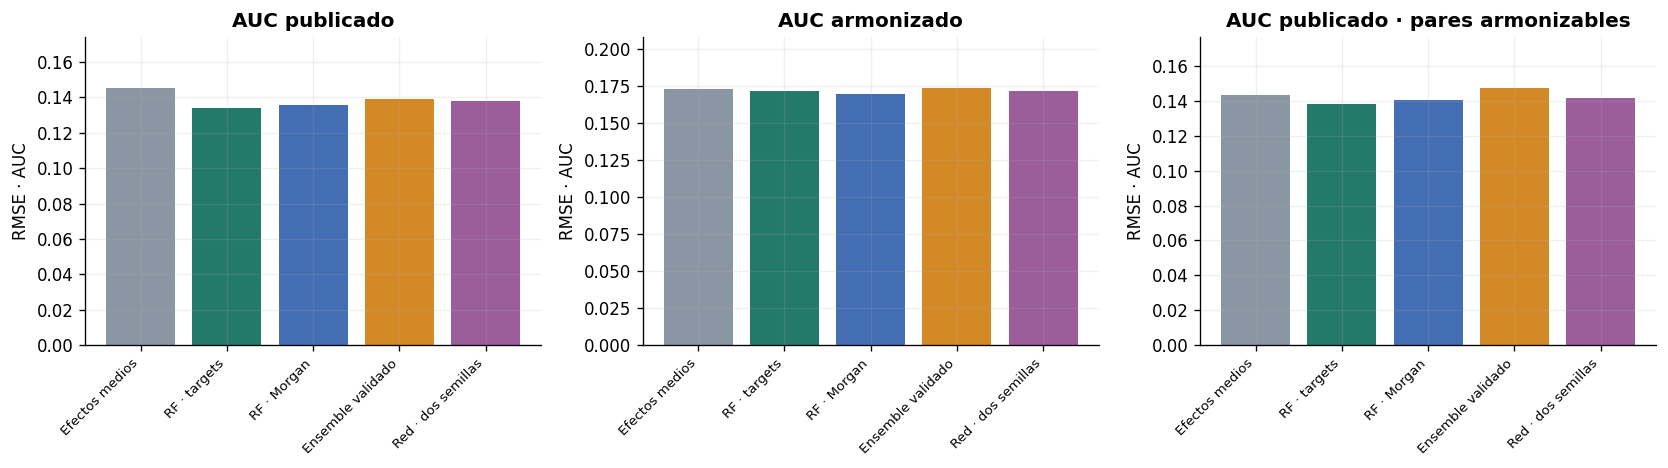

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, case, title in zip(axes, ["published_transfer", "harmonized_transfer", "matched_published_transfer"],
                           ["AUC publicado", "AUC armonizado", "AUC publicado · pares armonizables"]):
    frame = M[M.case.eq(case)].set_index("label").reindex(ORDER)
    ax.bar(range(5), frame.rmse, color=[COLORS[k] for k in ORDER])
    ax.set_xticks(range(5), [LABELS[k] for k in ORDER], rotation=45, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylabel("RMSE · AUC"); ax.set_ylim(0, frame.rmse.max() * 1.2)
save(fig, "05_source_only_transfer")

## 6. Adaptación supervisada al dominio PRISM

Se asignan células PRISM completas mediante semilla fija, sin mirar respuestas:
20% train de adaptación, 10% validación, 20% calibración y 50% evaluación.
La validación elige entre ajuste afín y ajustes afines con offsets químicos regularizados.
Después se reajusta sobre el 30% de desarrollo; calibración y test no ajustan parámetros.

Esto mide transferencia **con etiquetas del dominio destino**, para compuestos presentes
en ese dominio. No demuestra generalización a fármacos nuevos ni a una cohorte externa
intacta. Las células reservadas en PRISM pueden tener datos en GDSC: no es cold-cell global.


,split,n_pairs,n_cells
0,calibration,2177,67
1,test,5419,168
2,train,2137,67
3,validation,1052,33


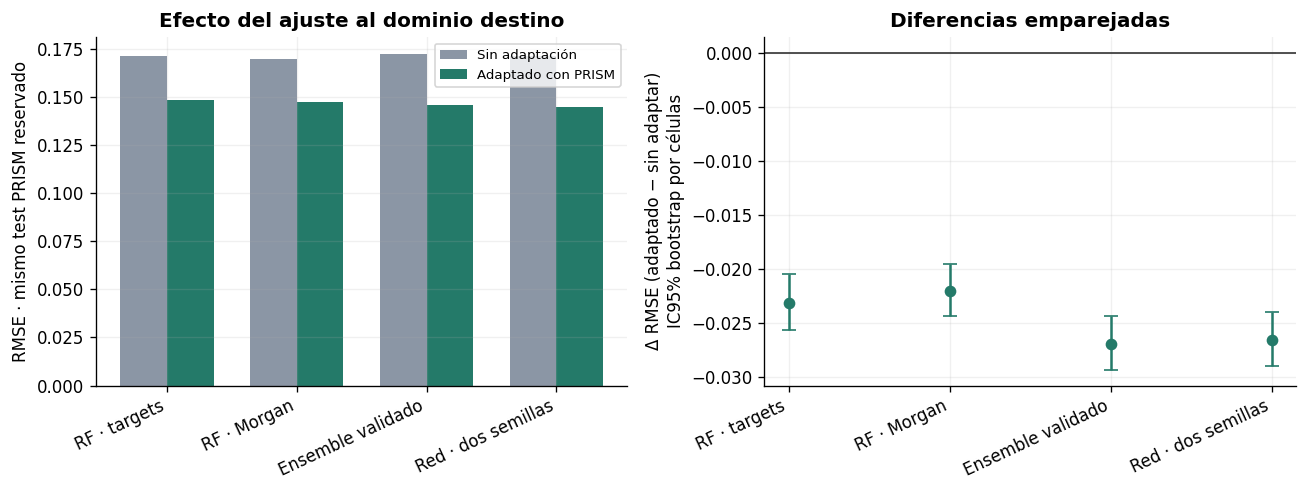

,model,method,rmse,spearman_per_drug
0,RF_targets,source_only_point_predictor,0.171418,0.216215
1,RF_targets,prism_supervised_adaptation,0.148201,0.216226
2,RF_morgan,source_only_point_predictor,0.169437,0.212755
3,RF_morgan,prism_supervised_adaptation,0.147347,0.212755
4,ensemble,source_only_point_predictor,0.172503,0.232719
5,ensemble,prism_supervised_adaptation,0.145561,0.232729
6,neural,source_only_point_predictor,0.171148,0.254350
7,neural,prism_supervised_adaptation,0.144575,0.254423


,model,rmse_clipping_only,n_clipped
0,RF_morgan,0.169437,0
1,RF_targets,0.171418,0
2,ensemble,0.172502,25
3,neural,0.171148,0


In [7]:
display(pd.DataFrame(S["plot_data"]["adaptation_populations"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
models = ["RF_targets", "RF_morgan", "ensemble", "neural"]
methods = ["source_only_point_predictor", "prism_supervised_adaptation"]
for j, method in enumerate(methods):
    frame = A[A.method.eq(method)].set_index("model").reindex(models)
    axes[0].bar(np.arange(4) + (j - 0.5) * 0.36, frame.rmse, width=0.36,
                color=["#8B96A5", "#247A69"][j], label=["Sin adaptación", "Adaptado con PRISM"][j])
delta = [S["adaptation_selection"][m]["paired_cell_bootstrap"] for m in models]
centres = np.array([d["rmse_delta"] for d in delta])
lo = np.array([d["ci95_low"] for d in delta]); hi = np.array([d["ci95_high"] for d in delta])
axes[1].errorbar(np.arange(4), centres, yerr=[centres-lo, hi-centres], fmt="o", color="#247A69", capsize=4)
axes[1].axhline(0, color="#333333", lw=1)
axes[1].set_ylabel("Δ RMSE (adaptado − sin adaptar)\nIC95% bootstrap por células")
for ax in axes: ax.set_xticks(np.arange(4), [LABELS[m] for m in models], rotation=25, ha="right")
axes[0].set_ylabel("RMSE · mismo test PRISM reservado"); axes[0].legend(fontsize=8)
axes[0].set_title("Efecto del ajuste al dominio destino"); axes[1].set_title("Diferencias emparejadas")
save(fig, "06_supervised_domain_adaptation")
display(A[["model", "method", "rmse", "spearman_per_drug"]])
display(pd.DataFrame(S["plot_data"]["clipping_controls"]))

## 7. Incertidumbre calibrada dentro del dominio destino

**Ambas** variantes de intervalos utilizan etiquetas del 20% de células PRISM de
calibración, incluso cuando su predictor puntual no está adaptado. Se usa el máximo
residuo absoluto de cada célula y el cuantil conformal finito con α=0.1.
La cobertura por fila puede ser alta mientras falla la cobertura de todos los fármacos
de una célula. La garantía formal necesita intercambiabilidad de células; una sola
partición exploratoria no la demuestra. La anchura permite valorar la utilidad práctica.


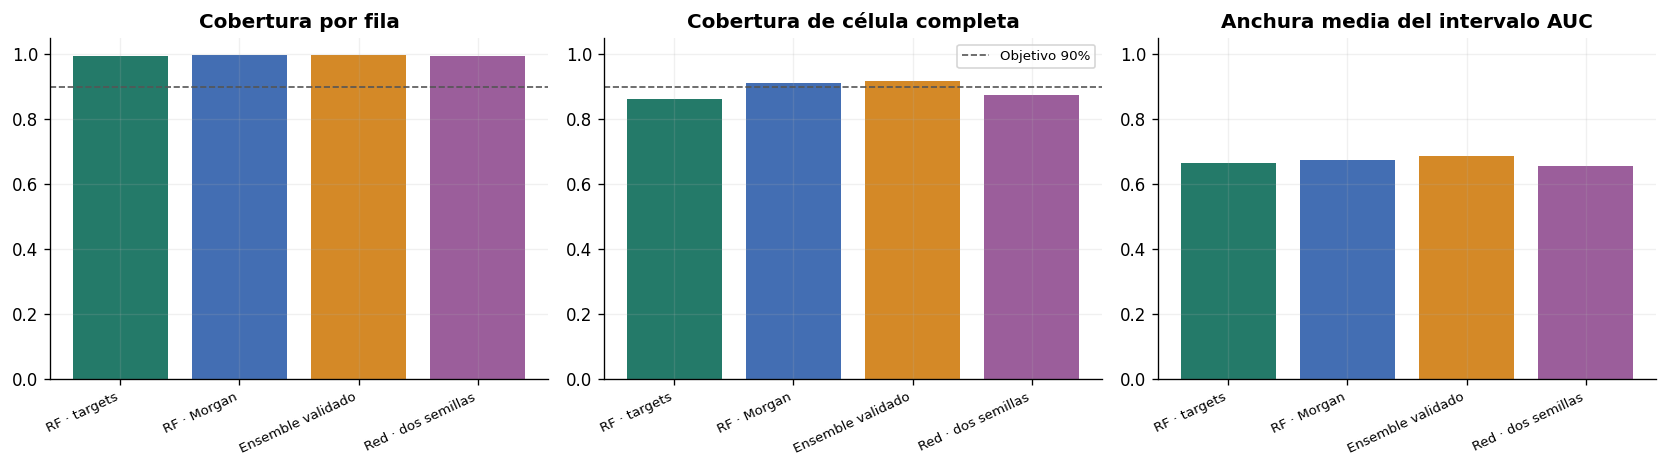

,model,method,n_groups,n_calibration_cells,row_coverage,whole_group_coverage,mean_width
0,RF_targets,source_only_point_predictor,168,67,0.995387,0.857143,0.764353
1,RF_targets,prism_supervised_adaptation,168,67,0.994833,0.863095,0.663459
2,RF_morgan,source_only_point_predictor,168,67,0.997601,0.928571,0.797794
3,RF_morgan,prism_supervised_adaptation,168,67,0.996863,0.910714,0.674208
4,ensemble,source_only_point_predictor,168,67,0.996678,0.898810,0.782646
5,ensemble,prism_supervised_adaptation,168,67,0.997047,0.916667,0.685886
6,neural,source_only_point_predictor,168,67,0.996863,0.910714,0.779578
7,neural,prism_supervised_adaptation,168,67,0.995571,0.875000,0.656775


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
adapted = A[A.method.eq("prism_supervised_adaptation")].set_index("model").reindex(models)
for ax, metric, title in zip(axes, ["row_coverage", "whole_group_coverage", "mean_width"],
                            ["Cobertura por fila", "Cobertura de célula completa", "Anchura media del intervalo AUC"]):
    ax.bar(range(4), adapted[metric], color=[COLORS[m] for m in models])
    ax.set_xticks(range(4), [LABELS[m] for m in models], rotation=25, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylim(0, 1.05)
    if metric != "mean_width": ax.axhline(0.9, ls="--", color="#555555", lw=1, label="Objetivo 90%")
axes[1].legend(fontsize=8)
save(fig, "07_target_domain_intervals")
display(A[["model", "method", "n_groups", "n_calibration_cells", "row_coverage", "whole_group_coverage", "mean_width"]])

## 8. Todos los pares del test reservado, sin recortar errores

Mapas de densidad con ejes y escala de color comunes, incluyendo predicciones que
queden fuera del dominio AUC [0,1]. Incluyen todos los
pares evaluados; no hay selección de ejemplos. La diagonal representa predicción exacta.
Los offsets químicos cambian el nivel medio de respuesta, pero por sí solos no mejoran
el ranking dentro de un fármaco.


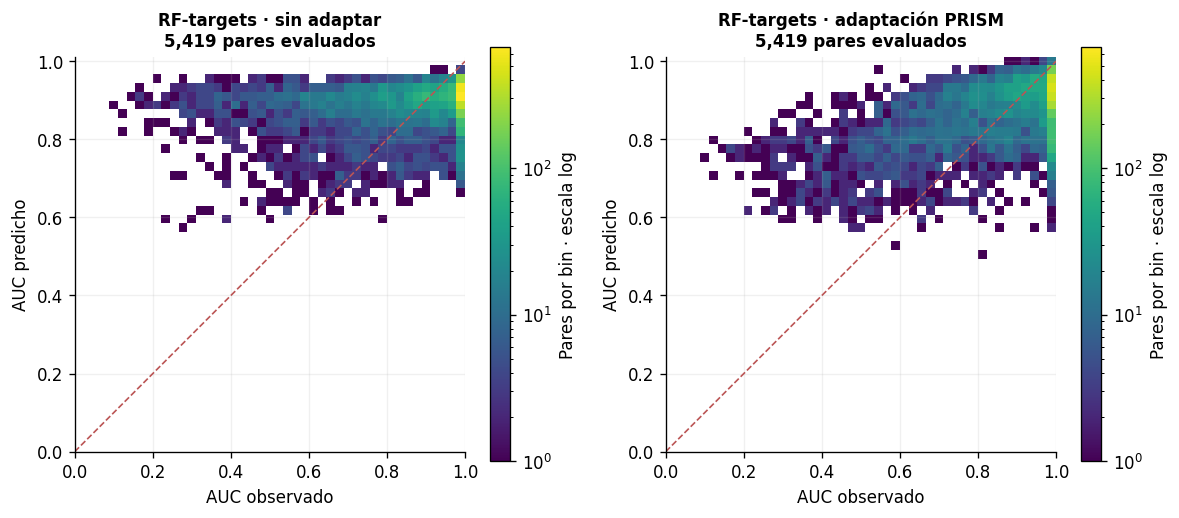

In [9]:
densities = [d for d in S["plot_data"]["densities"] if d["model"] == "RF_targets"]
vmax = max(np.max(d["counts"]) for d in densities)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, method, title in zip(axes, methods, ["RF-targets · sin adaptar", "RF-targets · adaptación PRISM"]):
    d = next(d for d in densities if d["method"] == method)
    counts = np.array(d["counts"]).T
    mesh = ax.pcolormesh(d["xedges"], d["yedges"], np.ma.masked_equal(counts, 0),
                          norm=LogNorm(vmin=1, vmax=vmax), cmap="viridis")
    ax.plot([0,1], [0,1], ls="--", color="#BB5555", lw=1)
    ax.set(xlabel="AUC observado", ylabel="AUC predicho")
    ax.set_title(f"{title}\n{d['n']:,} pares evaluados", fontsize=10)
    ax.set_aspect("equal"); fig.colorbar(mesh, ax=ax, label="Pares por bin · escala log")
save(fig, "08_adaptation_density")

## 9. Protocolo, reproducibilidad e interpretación

Los modelos y sus scalers se guardaron, y las predicciones se repitieron después de
recargar los pesos (delta exigida cero en esta ejecución). Se conservaron todas las curvas
y candidatos de validación, incluidos los que perdieron. El snapshot compacto verifica
los hashes de todos los artefactos del nuevo experimento antes de exportarse.

La referencia stable v1 continúa siendo la versión certificada. Este seguimiento usa
sus features guardadas: **no** es un nuevo entrenamiento desde datos crudos con el lock
original. Dos semillas reducen variabilidad de la red, pero no cuantifican toda la
incertidumbre del ajuste ni resuelven la escasez de compuestos y de evidencia farmacológica.
La red también cambia los bloques de entrada frente a RF-targets: una eventual ganancia
no puede atribuirse exclusivamente a la arquitectura sin comparar los mismos inputs.

Referencias que motivan la comparación exigente de modelos y el uso de información de
targets: [DrEval (2026)](https://www.nature.com/articles/s41467-026-72903-w) y
[DTLCDR (2025)](https://pmc.ncbi.nlm.nih.gov/articles/PMC12491712/).


In [10]:
display(pd.DataFrame([S["environment"]]))
selections = [{"case": case, "weights": value["weights"],
                "members": value["members"]} for case, value in S["ensemble_selections"].items()]
display(pd.DataFrame(selections))
print("Snapshot SHA-256:", hashlib.sha256(SOURCE.read_bytes()).hexdigest())
print("Figuras exportadas:", len(list(OUT.glob("*.png"))))

,python,packages,stable_environment
0,3.11.14,"{'numpy': '1.26.4', 'pandas': '2.3.3', 'scikit...",False


,case,weights,members
0,cold_drug_fold_0,"[1.0, 0.0, 0.0]","[RF_targets_expression_pca, RF_morgan_expressi..."
1,cold_drug_fold_1,"[0.75, 0.0, 0.25]","[RF_targets_expression_pca, RF_morgan_expressi..."
2,cold_drug_fold_2,"[0.5, 0.25, 0.25]","[RF_targets_expression_pca, RF_morgan_expressi..."
3,cold_drug_fold_3,"[0.5, 0.0, 0.5]","[RF_targets_expression_pca, RF_morgan_expressi..."
4,cold_drug_fold_4,"[0.5, 0.5, 0.0]","[RF_targets_expression_pca, RF_morgan_expressi..."
5,published_transfer,"[0.0, 0.0, 1.0]","[RF_targets_expression_pca, RF_morgan_expressi..."
6,harmonized_transfer,"[0.0, 0.0, 1.0]","[RF_targets_expression_pca, RF_morgan_expressi..."
7,matched_published_transfer,"[0.0, 0.0, 1.0]","[RF_targets_expression_pca, RF_morgan_expressi..."


Snapshot SHA-256: 964985ecedb0b7fef4f5640fa8f63b34be5d810f8e7f52c30fd1a06a53ebba15
Figuras exportadas: 8
